**Problem Understanding**

*Accuracy measures the overall percentage of correct predictions.

*In CKD severity classification, not all classification errors have the same consequences.

*Underestimating disease severity may be more concerning than confusing two adjacent stages.

*Model evaluation should consider both overall performance and class-specific errors.

*The final model should be selected based on predefined evaluation objectives, not accuracy alone.

*Feature selection should consider the prediction objective and how the target was created.

*Data leakage occurs when model training uses information that would not legitimately be available for the intended prediction.

*A high accuracy does not necessarily mean the model has learned a useful or generalizable relationship.

In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [70]:
import os
os.listdir("/content")

['.config',
 'Training_CKD_dataset.csv',
 'Testing_CKD_dataset.csv',
 'sample_data']

In [ ]:
df = pd.read_csv("/content/Training_CKD_dataset.csv")
print("Training dataset loaded successfully.")

Training dataset loaded successfully.


In [73]:
test_df = pd.read_csv("/content/Testing_CKD_dataset.csv")
print("Testing dataset loaded successfully")
print("Testing shape:", test_df.shape)

Testing dataset loaded successfully
Testing shape: (4800, 36)


In [71]:
print("Training shape:", df.shape)

Training shape: (21000, 36)


In [72]:
df.head()

,Target,Age,Gender,BMI,Systolic_BP,Diastolic_BP,Heart_Rate,Serum_Creatinine,Blood_Urea_Nitrogen,eGFR,Urine_Albumin,Urine_Protein,Albumin_Creatinine_Ratio,Urine_Specific_Gravity,Sodium,Potassium,Calcium,Phosphorus,Chloride,Bicarbonate,Hemoglobin,RBC_Count,WBC_Count,Platelet_Count,Packed_Cell_Volume,Blood_Glucose_Random,Fasting_Glucose,HbA1c,Cholesterol,Triglycerides,Serum_Albumin,Total_Protein,Diabetes,Hypertension,Smoking_Status,Family_History_Kidney
0,Healthy Kidney,29,1,28,97,69,99,0,12,95,6,1,18,1.026314,140,3,10,3,99,23,15,5.483781,8891,287217,43,86,96,7.547874,204,120,4,7.091259,Yes,Yes,Yes,Yes
1,Severe CKD (Stage 4),43,0,18,165,100,67,5,87,28,318,240,576,1.008521,143,5,9,6,109,18,9,4.265274,8208,299279,27,102,88,7.287338,166,277,2,7.875167,Yes,Yes,Yes,No
2,Healthy Kidney,77,0,32,116,63,101,0,16,100,1,5,26,1.010186,143,4,8,2,101,25,16,5.465182,5979,388400,44,94,82,9.114854,246,299,4,7.083558,No,No,Yes,No
3,Healthy Kidney,83,0,24,93,75,87,0,10,101,11,5,13,1.028396,138,3,10,3,103,27,13,5.807958,7007,392918,44,179,82,7.286450,173,285,4,6.428780,Yes,No,No,Yes
4,Healthy Kidney,38,1,19,111,70,92,0,10,102,9,1,16,1.027411,136,4,9,2,108,27,13,5.399106,8796,375143,47,189,106,8.376492,266,294,4,7.852894,Yes,No,Yes,No


Now we have in the first 5 rows in the target column only 2 classes

So now we need to know the values of this column to know what are the target of our model

In [62]:
df["Target"].unique()

array(['Healthy Kidney', 'Severe CKD (Stage 4)', 'Mild CKD (Stage 1–2)',
       'Moderate CKD (Stage 3)', 'Kidney Failure (Stage 5)'], dtype=object)

In [63]:
df["Target"].value_counts()

,count
Target,
Healthy Kidney,15744
Mild CKD (Stage 1–2),2491
Moderate CKD (Stage 3),1489
Severe CKD (Stage 4),856
Kidney Failure (Stage 5),420


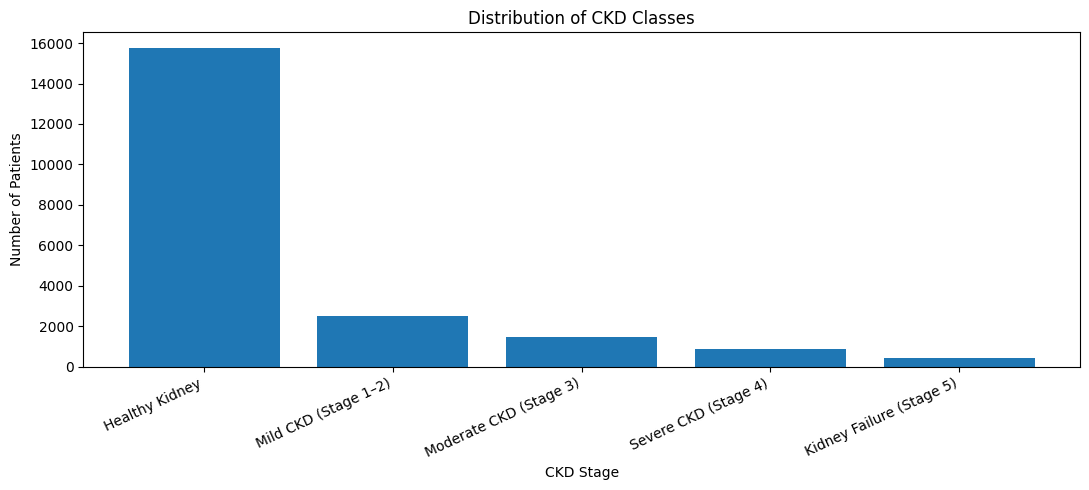

In [75]:
target_counts = df["Target"].value_counts()

plt.figure(figsize=(11, 5))
plt.bar(target_counts.index, target_counts.values)

plt.title("Distribution of CKD Classes")
plt.xlabel("CKD Stage")
plt.ylabel("Number of Patients")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

This to avoid overfitting, becuase for exmaple if I have int he ifrst class 3000 and in the second class 10, this means the model will barely learn on predicitng the second class.

This will lead us to the usage of the recall

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21000 entries, 0 to 20999
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Target                    21000 non-null  object 
 1   Age                       21000 non-null  int64  
 2   Gender                    21000 non-null  int64  
 3   BMI                       21000 non-null  int64  
 4   Systolic_BP               21000 non-null  int64  
 5   Diastolic_BP              21000 non-null  int64  
 6   Heart_Rate                21000 non-null  int64  
 7   Serum_Creatinine          21000 non-null  int64  
 8   Blood_Urea_Nitrogen       21000 non-null  int64  
 9   eGFR                      21000 non-null  int64  
 10  Urine_Albumin             21000 non-null  int64  
 11  Urine_Protein             21000 non-null  int64  
 12  Albumin_Creatinine_Ratio  21000 non-null  int64  
 13  Urine_Specific_Gravity    21000 non-null  float64
 14  Sodium

Hypertension : occurs when the force of blood pushing against your artery walls is consistently too high

BMI : Weight

eGFR : is a blood test calculation that measures how well your kidneys filter waste from your blood

HbA1c : measures your average blood sugar levels over the past two to three months by checking the amount of glucose attached to your red blood cells

No nulls doesn't mean there are no empty cells, maybe we have "unknown" in the column and it will not be considered as null

In [65]:

categorical_cols = [
    "Gender",
    "Diabetes",
    "Hypertension",
    "Smoking_Status",
    "Family_History_Kidney"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


Gender:
[1 0]

Diabetes:
['Yes' 'No']

Hypertension:
['Yes' 'No']

Smoking_Status:
['Yes' 'No']

Family_History_Kidney:
['Yes' 'No']


In [66]:
df.describe()

,Age,Gender,BMI,Systolic_BP,Diastolic_BP,Heart_Rate,Serum_Creatinine,Blood_Urea_Nitrogen,eGFR,Urine_Albumin,Urine_Protein,Albumin_Creatinine_Ratio,Urine_Specific_Gravity,Sodium,Potassium,Calcium,Phosphorus,Chloride,Bicarbonate,Hemoglobin,RBC_Count,WBC_Count,Platelet_Count,Packed_Cell_Volume,Blood_Glucose_Random,Fasting_Glucose,HbA1c,Cholesterol,Triglycerides,Serum_Albumin,Total_Protein
count,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000
mean,51.951905,0.500619,25.977571,113.497619,75.280857,84.280714,0.629571,21.682048,91.426095,59.986905,31.220524,68.929857,1.017498,139.492190,3.720238,9.004000,2.969667,102.488524,23.286048,13.449476,4.997753,7493.323000,300422.551571,42.167238,134.330524,99.473762,6.998247,214.411762,199.511571,3.598048,6.507856
std,18.796090,0.500012,4.890439,19.151820,12.106952,14.387748,1.482399,20.800122,26.787045,136.148540,73.192300,155.758117,0.007241,2.871809,0.826700,0.817381,1.101663,4.044394,2.949200,2.318597,0.578429,2019.807219,86546.236256,5.496877,37.623833,17.300907,1.736593,37.451581,58.167742,0.764034,0.865395
min,20.000000,0.000000,18.000000,90.000000,60.000000,60.000000,0.000000,7.000000,5.000000,0.000000,0.000000,0.000000,1.005004,135.000000,3.000000,8.000000,2.000000,96.000000,10.000000,5.000000,4.000061,4000.000000,150022.000000,20.000000,70.000000,70.000000,4.000855,150.000000,100.000000,1.000000,5.000065
25%,36.000000,0.000000,22.000000,99.000000,66.000000,72.000000,0.000000,11.000000,89.000000,6.000000,3.000000,9.000000,1.011137,137.000000,3.000000,8.000000,2.000000,99.000000,22.000000,13.000000,4.491671,5738.000000,225571.000000,40.000000,102.000000,84.000000,5.509804,182.000000,149.000000,3.000000,5.757357
50%,52.000000,1.000000,26.000000,110.000000,73.000000,84.000000,0.000000,15.000000,99.000000,13.000000,6.000000,20.000000,1.017565,139.000000,4.000000,9.000000,3.000000,102.000000,24.000000,14.000000,4.997454,7504.000000,300718.000000,43.000000,134.000000,99.000000,7.002234,214.000000,199.000000,4.000000,6.520847
75%,68.000000,1.000000,30.000000,120.000000,80.000000,97.000000,1.000000,20.000000,109.000000,20.000000,10.000000,30.000000,1.023762,142.000000,4.000000,10.000000,3.000000,106.000000,26.000000,15.000000,5.500192,9234.000000,375397.250000,46.000000,167.000000,114.000000,8.501457,247.000000,250.000000,4.000000,7.254656
max,84.000000,1.000000,34.000000,189.000000,119.000000,109.000000,9.000000,149.000000,119.000000,999.000000,499.000000,1199.000000,1.029999,144.000000,8.000000,10.000000,8.000000,109.000000,27.000000,16.000000,5.999995,10999.000000,449942.000000,49.000000,199.000000,129.000000,9.999904,279.000000,299.000000,4.000000,7.999568


In [68]:
df["Serum_Creatinine"].value_counts().sort_index()

,count
Serum_Creatinine,
0,15744
1,2491
2,788
3,701
4,442
5,414
6,86
7,99
8,111


Creatinine level can never be 0

crosstab : counts the frequencies

In [67]:
pd.crosstab(
    df["Serum_Creatinine"],
    df["Target"]
)

Target,Healthy Kidney,Kidney Failure (Stage 5),Mild CKD (Stage 1–2),Moderate CKD (Stage 3),Severe CKD (Stage 4)
Serum_Creatinine,,,,,
0,15744,0,0,0,0
1,0,0,2491,0,0
2,0,0,0,788,0
3,0,0,0,701,0
4,0,0,0,0,442
5,0,0,0,0,414
6,0,86,0,0,0
7,0,99,0,0,0
8,0,111,0,0,0


This shows the the "zero" in creatinine is not a zero, it's a class

In [76]:
X = df.drop(columns=["Target"])
y = df["Target"]

In [82]:
X.shape

(21000, 35)

In [78]:
print(X.columns.tolist())

['Age', 'Gender', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Serum_Creatinine', 'Blood_Urea_Nitrogen', 'eGFR', 'Urine_Albumin', 'Urine_Protein', 'Albumin_Creatinine_Ratio', 'Urine_Specific_Gravity', 'Sodium', 'Potassium', 'Calcium', 'Phosphorus', 'Chloride', 'Bicarbonate', 'Hemoglobin', 'RBC_Count', 'WBC_Count', 'Platelet_Count', 'Packed_Cell_Volume', 'Blood_Glucose_Random', 'Fasting_Glucose', 'HbA1c', 'Cholesterol', 'Triglycerides', 'Serum_Albumin', 'Total_Protein', 'Diabetes', 'Hypertension', 'Smoking_Status', 'Family_History_Kidney']


Our main problem now is "Serum Creatinine, eGFR are already defining the stages so training won't be generalized as we want it

In [84]:
X_without = X.drop(
    columns=["Serum_Creatinine", "eGFR"]
)
print(X_without.shape)

(21000, 33)


In [86]:
yes_no_cols = [
    "Diabetes",
    "Hypertension",
    "Smoking_Status",
    "Family_History_Kidney"
]

X_without[yes_no_cols] = (
    X_without[yes_no_cols]
    .replace({"Yes": 1, "No": 0})
)

/tmp/ipykernel_694/153815795.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({"Yes": 1, "No": 0})


In [87]:
for col in yes_no_cols:
    print(col, X_without[col].unique())

Diabetes [1 0]
Hypertension [1 0]
Smoking_Status [1 0]
Family_History_Kidney [1 0]


Now we have all the categorical columns having the binary encoding

In [91]:
X_without["Age"].describe()

,Age
count,21000.000000
mean,51.951905
std,18.796090
min,20.000000
25%,36.000000
50%,52.000000
75%,68.000000
max,84.000000


In [95]:
numeric_cols = X_without.select_dtypes(
    include="number"
).columns.drop("Gender")

Q1 = X_without[numeric_cols].quantile(0.25)
Q3 = X_without[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (X_without[numeric_cols] < lower_bound) |
    (X_without[numeric_cols] > upper_bound)
)

outlier_report = pd.DataFrame({
    "min": X_without[numeric_cols].min(),
    "max": X_without[numeric_cols].max(),
    "lower_bound": lower_bound,
    "upper_bound": upper_bound,
    "outlier_count": outlier_mask.sum()
})

outlier_report["outlier_%"] = (
    outlier_report["outlier_count"] / len(X_without) * 100
)

display(outlier_report.sort_values("outlier_count", ascending=False))

,min,max,lower_bound,upper_bound,outlier_count,outlier_%
Urine_Protein,0.000000,499.000000,-7.500000,20.500000,4574,21.780952
Urine_Albumin,0.000000,999.000000,-15.000000,41.000000,4560,21.714286
Albumin_Creatinine_Ratio,0.000000,1199.000000,-22.500000,61.500000,4132,19.676190
Blood_Urea_Nitrogen,7.000000,149.000000,-2.500000,33.500000,2929,13.947619
Phosphorus,2.000000,8.000000,0.500000,4.500000,2022,9.628571
Hemoglobin,5.000000,16.000000,10.000000,18.000000,1802,8.580952
Systolic_BP,90.000000,189.000000,67.500000,151.500000,1194,5.685714
Packed_Cell_Volume,20.000000,49.000000,31.000000,55.000000,1078,5.133333
Diastolic_BP,60.000000,119.000000,45.000000,101.000000,1073,5.109524
Potassium,3.000000,8.000000,1.500000,5.500000,824,3.923810


In [96]:
binary_cols = [
    "Gender",
    "Diabetes",
    "Hypertension",
    "Smoking_Status",
    "Family_History_Kidney"
]

display(
    outlier_report
    .drop(index=binary_cols, errors="ignore")
    .sort_values("outlier_count", ascending=False)
)

,min,max,lower_bound,upper_bound,outlier_count,outlier_%
Urine_Protein,0.000000,499.000000,-7.500000,20.500000,4574,21.780952
Urine_Albumin,0.000000,999.000000,-15.000000,41.000000,4560,21.714286
Albumin_Creatinine_Ratio,0.000000,1199.000000,-22.500000,61.500000,4132,19.676190
Blood_Urea_Nitrogen,7.000000,149.000000,-2.500000,33.500000,2929,13.947619
Phosphorus,2.000000,8.000000,0.500000,4.500000,2022,9.628571
Hemoglobin,5.000000,16.000000,10.000000,18.000000,1802,8.580952
Systolic_BP,90.000000,189.000000,67.500000,151.500000,1194,5.685714
Packed_Cell_Volume,20.000000,49.000000,31.000000,55.000000,1078,5.133333
Diastolic_BP,60.000000,119.000000,45.000000,101.000000,1073,5.109524
Potassium,3.000000,8.000000,1.500000,5.500000,824,3.923810


In [97]:
cols_to_check = [
    "Urine_Protein",
    "Urine_Albumin",
    "Albumin_Creatinine_Ratio",
    "Blood_Urea_Nitrogen"
]

for col in cols_to_check:
    print(f"\n{col}")
    display(
        df.groupby("Target")[col].agg(["min", "median", "max"])
    )


Urine_Protein


,min,median,max
Target,,,
Healthy Kidney,0,5.0,9
Kidney Failure (Stage 5),302,399.0,499
Mild CKD (Stage 1–2),10,30.0,49
Moderate CKD (Stage 3),50,101.0,149
Severe CKD (Stage 4),150,223.0,299



Urine_Albumin


,min,median,max
Target,,,
Healthy Kidney,0,10.0,19
Kidney Failure (Stage 5),500,752.0,999
Mild CKD (Stage 1–2),20,60.0,99
Moderate CKD (Stage 3),100,206.0,299
Severe CKD (Stage 4),300,402.0,499



Albumin_Creatinine_Ratio


,min,median,max
Target,,,
Healthy Kidney,0,14.0,29
Kidney Failure (Stage 5),600,895.0,1199
Mild CKD (Stage 1–2),30,65.0,99
Moderate CKD (Stage 3),100,198.0,299
Severe CKD (Stage 4),300,444.5,599



Blood_Urea_Nitrogen


,min,median,max
Target,,,
Healthy Kidney,7,13.0,19
Kidney Failure (Stage 5),90,119.0,149
Mild CKD (Stage 1–2),20,27.0,34
Moderate CKD (Stage 3),35,47.0,59
Severe CKD (Stage 4),60,74.0,89


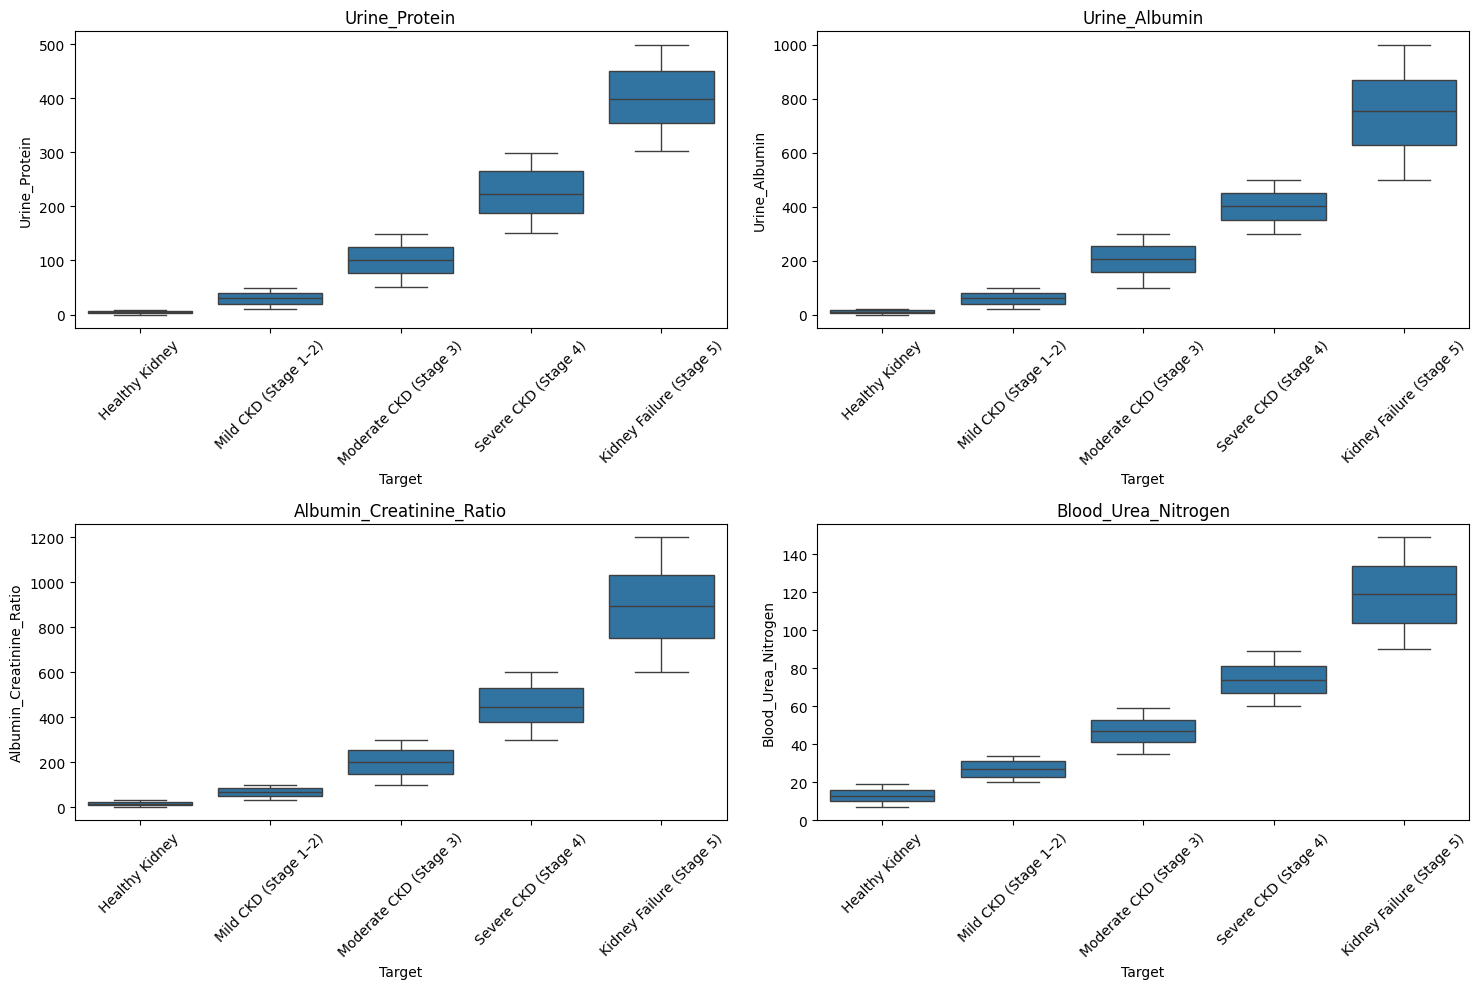

In [103]:
plot_cols = [
    "Urine_Protein",
    "Urine_Albumin",
    "Albumin_Creatinine_Ratio",
    "Blood_Urea_Nitrogen"
]

stage_order = [
    "Healthy Kidney",
    "Mild CKD (Stage 1–2)",
    "Moderate CKD (Stage 3)",
    "Severe CKD (Stage 4)",
    "Kidney Failure (Stage 5)"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(
        data=df,
        x="Target",
        y=col,
        order=stage_order,
        ax=ax
    )
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [98]:
remaining_cols = [
    "Phosphorus",
    "Hemoglobin",
    "Systolic_BP",
    "Packed_Cell_Volume",
    "Diastolic_BP",
    "Potassium",
    "Bicarbonate",
    "Serum_Albumin"
]

for col in remaining_cols:
    print(f"\n{col}")
    display(df.groupby("Target")[col].agg(["min", "median", "max"]))


Phosphorus


,min,median,max
Target,,,
Healthy Kidney,2,2.0,3
Kidney Failure (Stage 5),6,7.0,8
Mild CKD (Stage 1–2),3,3.0,4
Moderate CKD (Stage 3),4,5.0,5
Severe CKD (Stage 4),5,6.0,6



Hemoglobin


,min,median,max
Target,,,
Healthy Kidney,13,15.0,16
Kidney Failure (Stage 5),5,6.0,7
Mild CKD (Stage 1–2),11,12.0,13
Moderate CKD (Stage 3),9,10.0,11
Severe CKD (Stage 4),7,8.0,9



Systolic_BP


,min,median,max
Target,,,
Healthy Kidney,90,104.0,119
Kidney Failure (Stage 5),160,176.0,189
Mild CKD (Stage 1–2),120,127.0,134
Moderate CKD (Stage 3),135,143.0,149
Severe CKD (Stage 4),150,160.0,169


... (6 outputs left out)


Bicarbonate


,min,median,max
Target,,,
Healthy Kidney,22,25.0,27
Kidney Failure (Stage 5),10,13.0,17
Mild CKD (Stage 1–2),20,22.0,23
Moderate CKD (Stage 3),18,20.0,21
Severe CKD (Stage 4),15,17.0,19



Serum_Albumin


,min,median,max
Target,,,
Healthy Kidney,4,4.0,4
Kidney Failure (Stage 5),1,1.0,1
Mild CKD (Stage 1–2),3,3.0,3
Moderate CKD (Stage 3),2,2.0,2
Severe CKD (Stage 4),2,2.0,2


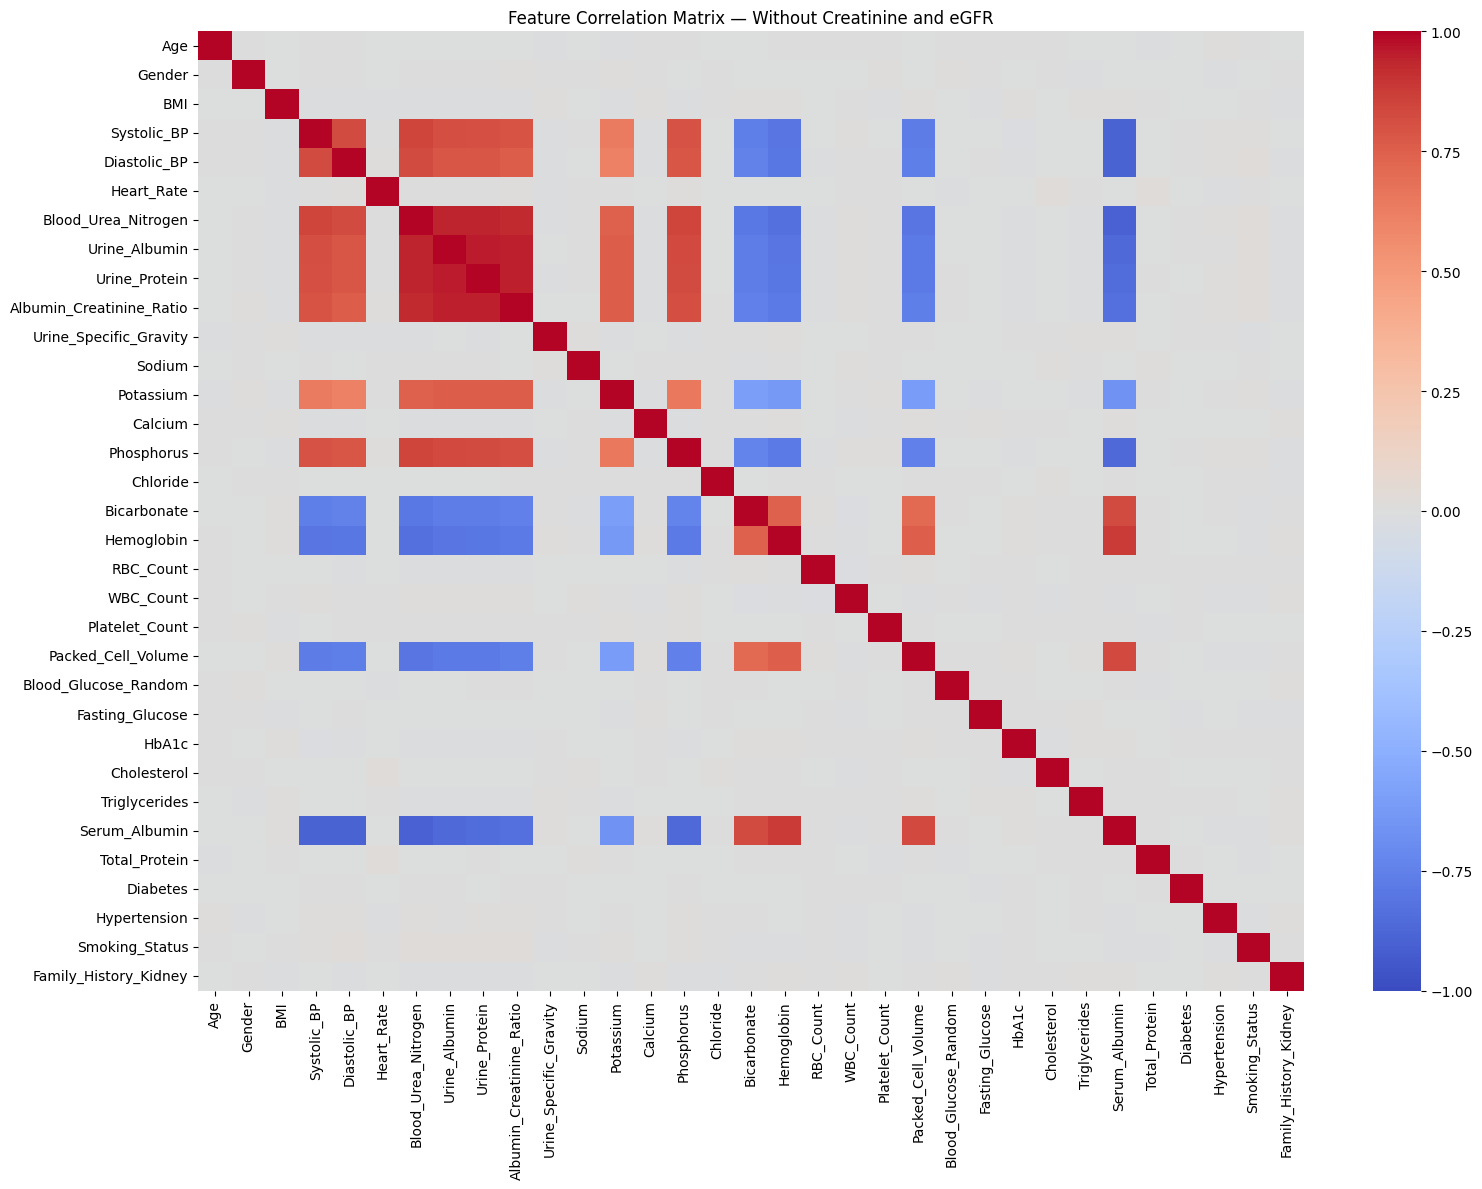

In [105]:
corr_matrix = X_without.corr()
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Feature Correlation Matrix — Without Creatinine and eGFR")
plt.tight_layout()
plt.show()

قريبة من +1: العمودان بيزيدوا مع بعض.

قريبة من -1: واحد بيزيد والتاني بيقل.

قريبة من 0: مفيش علاقة خطية واضحة بينهما.

In [108]:
train_idx, val_idx = train_test_split(
    X.index,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Experiment 1: Without Serum_Creatinine and eGFR
X_train_without = X_without.loc[train_idx]
X_val_without = X_without.loc[val_idx]

# Experiment 2: With all features
X_train_all = X.loc[train_idx]
X_val_all = X.loc[val_idx]

# Same target labels for both experiments
y_train = y.loc[train_idx]
y_val = y.loc[val_idx]

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True).round(3))

Training rows: 16800
Validation rows: 4200

Training class distribution:
Target
Healthy Kidney              0.750
Mild CKD (Stage 1–2)        0.119
Moderate CKD (Stage 3)      0.071
Severe CKD (Stage 4)        0.041
Kidney Failure (Stage 5)    0.020
Name: proportion, dtype: float64

Validation class distribution:
Target
Healthy Kidney              0.750
Mild CKD (Stage 1–2)        0.119
Moderate CKD (Stage 3)      0.071
Severe CKD (Stage 4)        0.041
Kidney Failure (Stage 5)    0.020
Name: proportion, dtype: float64


In [109]:
binary_cols = [
    "Diabetes",
    "Hypertension",
    "Smoking_Status",
    "Family_History_Kidney"
]

for col in binary_cols:
    X_train_all[col] = X_train_all[col].replace({"Yes": 1, "No": 0})
    X_val_all[col] = X_val_all[col].replace({"Yes": 1, "No": 0})

print("Experiment 1 — training shape:", X_train_without.shape)
print("Experiment 2 — training shape:", X_train_all.shape)

print("\nNon-numeric columns in Experiment 2:")
print(X_train_all.select_dtypes(exclude="number").columns.tolist())
print(X_val_all.select_dtypes(exclude="number").columns.tolist())

Experiment 1 — training shape: (16800, 33)
Experiment 2 — training shape: (16800, 35)

Non-numeric columns in Experiment 2:
[]
[]


/tmp/ipykernel_694/4266492861.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train_all[col] = X_train_all[col].replace({"Yes": 1, "No": 0})
/tmp/ipykernel_694/4266492861.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val_all[col] = X_val_all[col].replace({"Yes": 1, "No": 0})


In [110]:
# Experiment 1: Without Serum_Creatinine and eGFR
scaler_without = StandardScaler()

X_train_without_scaled = scaler_without.fit_transform(X_train_without)
X_val_without_scaled = scaler_without.transform(X_val_without)

# Experiment 2: With all features
scaler_all = StandardScaler()

X_train_all_scaled = scaler_all.fit_transform(X_train_all)
X_val_all_scaled = scaler_all.transform(X_val_all)

print("Without markers:")
print(X_train_without_scaled.shape, X_val_without_scaled.shape)

print("\nWith all features:")
print(X_train_all_scaled.shape, X_val_all_scaled.shape)

Without markers:
(16800, 33) (4200, 33)

With all features:
(16800, 35) (4200, 35)


Experiment 1 — Without kidney markers
                          precision    recall  f1-score   support

          Healthy Kidney      1.000     1.000     1.000      3149
Kidney Failure (Stage 5)      1.000     1.000     1.000        84
    Mild CKD (Stage 1–2)      1.000     1.000     1.000       498
  Moderate CKD (Stage 3)      1.000     1.000     1.000       298
    Severe CKD (Stage 4)      1.000     1.000     1.000       171

                accuracy                          1.000      4200
               macro avg      1.000     1.000     1.000      4200
            weighted avg      1.000     1.000     1.000      4200



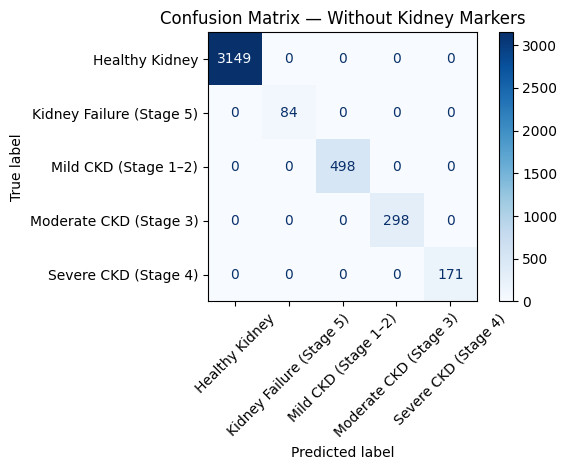

In [111]:
# Experiment 1: Without Serum_Creatinine and eGFR
model_without = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model_without.fit(X_train_without_scaled, y_train)

y_pred_without = model_without.predict(X_val_without_scaled)

print("Experiment 1 — Without kidney markers")
print(classification_report(y_val, y_pred_without, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_without,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Confusion Matrix — Without Kidney Markers")
plt.tight_layout()
plt.show()

Experiment 2 — With all features
                          precision    recall  f1-score   support

          Healthy Kidney      1.000     1.000     1.000      3149
Kidney Failure (Stage 5)      1.000     1.000     1.000        84
    Mild CKD (Stage 1–2)      1.000     1.000     1.000       498
  Moderate CKD (Stage 3)      1.000     1.000     1.000       298
    Severe CKD (Stage 4)      1.000     1.000     1.000       171

                accuracy                          1.000      4200
               macro avg      1.000     1.000     1.000      4200
            weighted avg      1.000     1.000     1.000      4200



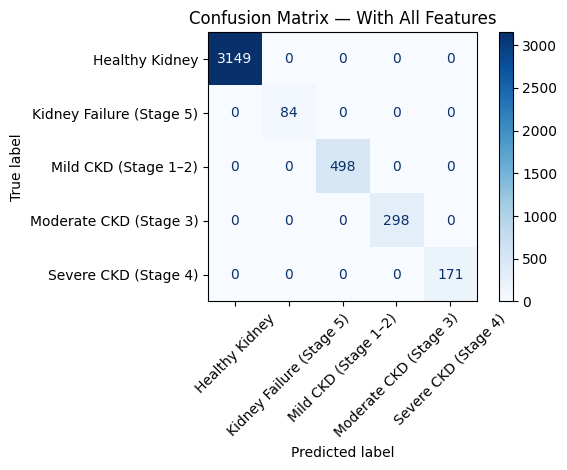

In [112]:
# Experiment 2: With all features
model_all = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model_all.fit(X_train_all_scaled, y_train)

y_pred_all = model_all.predict(X_val_all_scaled)

print("Experiment 2 — With all features")
print(classification_report(y_val, y_pred_all, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_all,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Confusion Matrix — With All Features")
plt.tight_layout()
plt.show()

In [117]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "SVM": SVC(
        class_weight="balanced",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

experiments = {
    "Without kidney markers": (
        X_train_without, X_val_without,
        X_train_without_scaled, X_val_without_scaled
    ),
    "With all features": (
        X_train_all, X_val_all,
        X_train_all_scaled, X_val_all_scaled
    )
}

In [118]:
model_results = []
trained_models = {}

for experiment_name, (X_tr, X_v, X_tr_scaled, X_v_scaled) in experiments.items():

    for model_name, model in models.items():

        if model_name in ["SVM", "KNN"]:
            train_data = X_tr_scaled
            val_data = X_v_scaled
        else:
            train_data = X_tr
            val_data = X_v

        model.fit(train_data, y_train)
        predictions = model.predict(val_data)

        model_results.append({
            "Experiment": experiment_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro Recall": recall_score(y_val, predictions, average="macro"),
            "Macro F1": f1_score(y_val, predictions, average="macro")
        })

        trained_models[(experiment_name, model_name)] = model

model_comparison = pd.DataFrame(model_results)
display(model_comparison.round(3))

,Experiment,Model,Accuracy,Macro Recall,Macro F1
0,Without kidney markers,Decision Tree,1.000,1.000,1.000
1,Without kidney markers,Random Forest,1.000,1.000,1.000
2,Without kidney markers,SVM,1.000,1.000,1.000
3,Without kidney markers,KNN,0.996,0.994,0.996
4,With all features,Decision Tree,1.000,1.000,1.000
5,With all features,Random Forest,1.000,1.000,1.000
6,With all features,SVM,1.000,1.000,1.000
7,With all features,KNN,0.999,0.998,0.999


Now we have a problem is that we trained in both experiments the same models so we can't compare them at the end

KNN — Without kidney markers
                          precision    recall  f1-score   support

          Healthy Kidney      0.996     1.000     0.998      3149
Kidney Failure (Stage 5)      1.000     1.000     1.000        84
    Mild CKD (Stage 1–2)      0.998     0.972     0.985       498
  Moderate CKD (Stage 3)      1.000     0.997     0.998       298
    Severe CKD (Stage 4)      1.000     1.000     1.000       171

                accuracy                          0.996      4200
               macro avg      0.999     0.994     0.996      4200
            weighted avg      0.996     0.996     0.996      4200



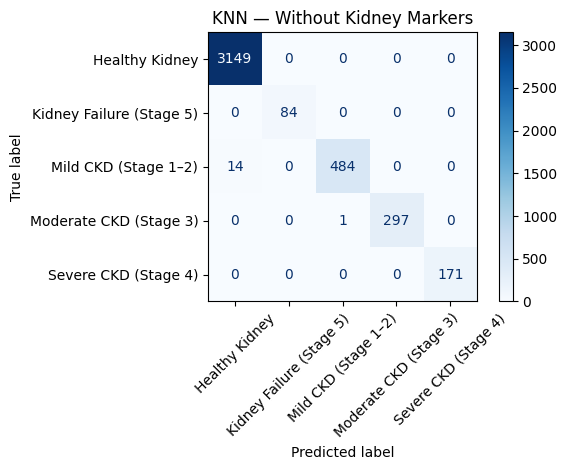

In [115]:
# KNN — Experiment 1: Without kidney markers
knn_without = KNeighborsClassifier(n_neighbors=5)
knn_without.fit(X_train_without_scaled, y_train)

knn_pred_without = knn_without.predict(X_val_without_scaled)

print("KNN — Without kidney markers")
print(classification_report(y_val, knn_pred_without, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    knn_pred_without,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("KNN — Without Kidney Markers")
plt.tight_layout()
plt.show()

KNN — With all features
                          precision    recall  f1-score   support

          Healthy Kidney      0.999     1.000     1.000      3149
Kidney Failure (Stage 5)      1.000     1.000     1.000        84
    Mild CKD (Stage 1–2)      0.998     0.994     0.996       498
  Moderate CKD (Stage 3)      1.000     0.997     0.998       298
    Severe CKD (Stage 4)      1.000     1.000     1.000       171

                accuracy                          0.999      4200
               macro avg      0.999     0.998     0.999      4200
            weighted avg      0.999     0.999     0.999      4200



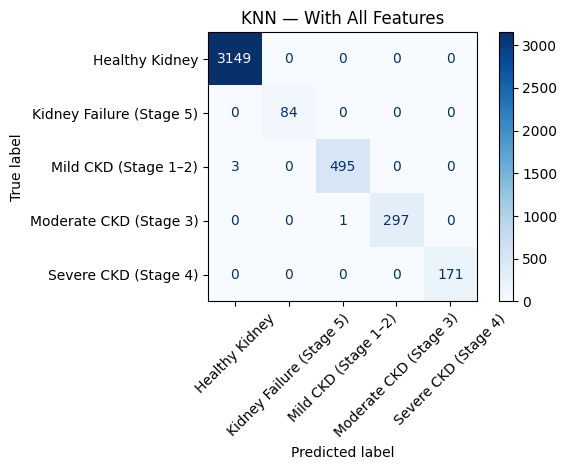

In [116]:
# KNN — Experiment 2: With all features
knn_all = KNeighborsClassifier(n_neighbors=5)
knn_all.fit(X_train_all_scaled, y_train)

knn_pred_all = knn_all.predict(X_val_all_scaled)

print("KNN — With all features")
print(classification_report(y_val, knn_pred_all, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    knn_pred_all,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("KNN — With All Features")
plt.tight_layout()
plt.show()

In [119]:
from sklearn.base import clone

trained_models = {}

for experiment_name, (X_tr, X_v, X_tr_scaled, X_v_scaled) in experiments.items():
    for model_name, model_template in models.items():
        model = clone(model_template)

        if model_name in ["SVM", "KNN"]:
            train_data = X_tr_scaled
        else:
            train_data = X_tr

        model.fit(train_data, y_train)

        trained_models[(experiment_name, model_name)] = model

print("Number of saved models:", len(trained_models))
print("Saved experiments and models:")
for key in trained_models:
    print(key)

Number of saved models: 8
Saved experiments and models:
('Without kidney markers', 'Decision Tree')
('Without kidney markers', 'Random Forest')
('Without kidney markers', 'SVM')
('Without kidney markers', 'KNN')
('With all features', 'Decision Tree')
('With all features', 'Random Forest')
('With all features', 'SVM')
('With all features', 'KNN')


In [120]:
from sklearn.base import clone

trained_models = {}

for experiment_name, (X_tr, X_v, X_tr_scaled, X_v_scaled) in experiments.items():
    for model_name, model_template in models.items():

        # Create a separate model for each experiment
        model = clone(model_template)

        if model_name in ["SVM", "KNN"]:
            train_data = X_tr_scaled
        else:
            train_data = X_tr

        model.fit(train_data, y_train)

        trained_models[(experiment_name, model_name)] = model

print("Number of saved models:", len(trained_models))
print("Saved experiments and models:")
for key in trained_models:
    print(key)

Number of saved models: 8
Saved experiments and models:
('Without kidney markers', 'Decision Tree')
('Without kidney markers', 'Random Forest')
('Without kidney markers', 'SVM')
('Without kidney markers', 'KNN')
('With all features', 'Decision Tree')
('With all features', 'Random Forest')
('With all features', 'SVM')
('With all features', 'KNN')


In [121]:
[name for name, value in globals().items()
 if isinstance(value, pd.DataFrame) and len(value) == 4800]

['model_df', 'test_df']

In [122]:
print("Test shape:", test_df.shape)
print("Test columns:", test_df.columns.tolist())

print("\nTarget exists:", "Target" in test_df.columns)

print("\nMissing features:")
print(X.columns.difference(test_df.columns).tolist())

print("\nExtra columns:")
print(test_df.columns.difference(X.columns).tolist())

Test shape: (4800, 36)
Test columns: ['Target', 'Age', 'Gender', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Serum_Creatinine', 'Blood_Urea_Nitrogen', 'eGFR', 'Urine_Albumin', 'Urine_Protein', 'Albumin_Creatinine_Ratio', 'Urine_Specific_Gravity', 'Sodium', 'Potassium', 'Calcium', 'Phosphorus', 'Chloride', 'Bicarbonate', 'Hemoglobin', 'RBC_Count', 'WBC_Count', 'Platelet_Count', 'Packed_Cell_Volume', 'Blood_Glucose_Random', 'Fasting_Glucose', 'HbA1c', 'Cholesterol', 'Triglycerides', 'Serum_Albumin', 'Total_Protein', 'Diabetes', 'Hypertension', 'Smoking_Status', 'Family_History_Kidney']

Target exists: True

Missing features:
[]

Extra columns:
['Target']


In [123]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
y_test = test_df["Target"]
X_test_all = test_df.drop(columns=["Target"])

# 2) Encode Yes/No columns exactly as in training
binary_cols = [
    "Diabetes",
    "Hypertension",
    "Smoking_Status",
    "Family_History_Kidney"
]

for col in binary_cols:
    X_test_all[col] = X_test_all[col].replace({"Yes": 1, "No": 0})

# 3) Match the training feature names AND order
X_test_all = X_test_all[X_train_all.columns]
X_test_without = X_test_all[X_train_without.columns]

# 4) Apply the scalers fitted on training data
X_test_all_scaled = scaler_all.transform(X_test_all)
X_test_without_scaled = scaler_without.transform(X_test_without)

# 5) Evaluate the saved models
test_results = []

test_experiments = {
    "Without kidney markers": (
        X_test_without,
        X_test_without_scaled,
        model_without
    ),
    "With all features": (
        X_test_all,
        X_test_all_scaled,
        model_all
    )
}

for experiment_name, (X_test_raw, X_test_scaled, logistic_model) in test_experiments.items():

    # Logistic Regression uses scaled features
    predictions = logistic_model.predict(X_test_scaled)

    test_results.append({
        "Experiment": experiment_name,
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Recall": recall_score(y_test, predictions, average="macro"),
        "Macro F1": f1_score(y_test, predictions, average="macro")
    })

    # Evaluate the other four saved models
    for model_name in models:
        model = trained_models[(experiment_name, model_name)]

        if model_name in ["SVM", "KNN"]:
            predictions = model.predict(X_test_scaled)
        else:
            predictions = model.predict(X_test_raw)

        test_results.append({
            "Experiment": experiment_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Macro Recall": recall_score(y_test, predictions, average="macro"),
            "Macro F1": f1_score(y_test, predictions, average="macro")
        })

final_test_results = pd.DataFrame(test_results)

display(
    final_test_results
    .sort_values(["Experiment", "Model"])
    .round(3)
)

/tmp/ipykernel_694/2918024350.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test_all[col] = X_test_all[col].replace({"Yes": 1, "No": 0})


,Experiment,Model,Accuracy,Macro Recall,Macro F1
6,With all features,Decision Tree,1.000,1.000,1.000
9,With all features,KNN,0.999,0.998,0.999
5,With all features,Logistic Regression,1.000,1.000,1.000
7,With all features,Random Forest,1.000,1.000,1.000
8,With all features,SVM,1.000,1.000,1.000
1,Without kidney markers,Decision Tree,1.000,1.000,1.000
4,Without kidney markers,KNN,0.996,0.993,0.996
0,Without kidney markers,Logistic Regression,1.000,1.000,1.000
2,Without kidney markers,Random Forest,1.000,1.000,1.000
3,Without kidney markers,SVM,1.000,1.000,1.000
